# Analyze metric correlations from transcriptomics cohort

In [1]:
import numpy as np
import pandas as pd
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
import glob
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
import json
import colorcet as cc
import re

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')
bold_prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')

In [2]:
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')

from analysis_helpers import *
import ast

def clean_mixed_types(val):
    if isinstance(val, str) and val.startswith('('):
        val = ast.literal_eval(val)
    
    return val[1] if isinstance(val, tuple) else val

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


## Create final dataset

This is very messy, my apologies. Essentially, the main runs worked, but a lot of rescue was needed to account for failed runs,
changes to method execution, or re-execution of metrics after bug fixes.

In [85]:
dirs = ['cpu_methods_1', 'cpu_methods_2', 'gpu_methods_2', 'cpu_methods_1_new_data', 'cpu_methods_2_new_data',
        'gpu_methods_2_new_data', 'llms_test', 'tian_multitech_rescue', 'sccobra_rescue', 'scanorama_rescue', 'ocat_rescue',
        'gedi_rescue', 'cyclone_rescue']
df = pd.concat([
    pd.read_csv(f'/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/{d}/metrics/all-metrics.csv') for d in dirs
])

In [86]:
# Rescued metrics
base = '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/'
exts = [
    'cd/7373374d8227bfd57d62dd6ab6135e/human_brain_cell_atlas-scvi-1-ALL_CLUSTER.csv',
    '4e/e280dd12e323f4728629c61fc28a07/human_brain_cell_atlas-scanvi-1-ALL_CLUSTER.csv',
    'dd/c53af1756ef3c7b45f58da78f2d13b/human_brain_cell_atlas-scphere-1-ALL_CLUSTER.csv',
    '95/098c0f74c6ef0a2ebce9b240ec6d89/human_brain_cell_atlas-scalex-1-ALL_CLUSTER.csv',
    '16/677b89ff15cd3728ea05312b674c70/human_brain_cell_atlas-scetm-1-ALL_CLUSTER.csv',
    '91/bc118537606de726455ac528d7b9fe/human_brain_cell_atlas-imap-1-ALL_CLUSTER.csv',
    '3f/e6b6139d2210bcacaa8672eecaa860/human_brain_cell_atlas-sccraft-1-ALL_CLUSTER.csv',
    '4e/24398147b570c1be7bef1e2de2c1ed/human_brain_cell_atlas-islander-1-ALL_CLUSTER.csv',
    '5c/0b4382738b07ade82452c8fbcf25a3/human_brain_cell_atlas-sccobra-1-ALL_CLUSTER.csv',
    '16/7ca3f23df5c7024c034144176e2aed/human_brain_cell_atlas-respan-1-ALL_CLUSTER.csv',
    '38/d66478336d5590d365177231eb3e58/human_brain_cell_atlas-sysvi-1-ALL_CLUSTER.csv',
    '4b/a49c2e309524097ce7a8e3caf719fc/human_brain_cell_atlas-clear-1-ALL_CLUSTER.csv',
    '53/9ad73a51385e4e9727b03fd41d4785/human_brain_cell_atlas-mnn-1-ALL_CLUSTER.csv',
    'e5/5e3ec0ea514d5731962a349c794b7d/human_brain_cell_atlas-harmony-1-ALL_CLUSTER.csv',
    '3c/d34f402c9dbadd9ad4397285ee784b/human_brain_cell_atlas-oneBigBlob-1-ALL_CLUSTER.csv',
    'd2/e7022729aa1ccf27375eecc8a08e6d/human_brain_cell_atlas-equidistant-1-ALL_CLUSTER.csv',
    'f8/680c5d48eed91dc851e857e41bb3a1/human_brain_cell_atlas-scanorama-1-ALL_CLUSTER.csv',
    'e0/c3977086f35a4e00ea63db1fcd3796/human_eoe-islander-1-BLOGREG.csv',  # IPR
    'c8/9693d2ae931af0aeffbe57e94a4a66/human_brain_cell_atlas-scetm-1-ALIGN.csv',
    '28/c90f661f6adfa45d72e7d9aaf0782a/human_brain_cell_atlas-sccraft-1-ALIGN.csv',
    '04/1601f29ab881d00e39af24513c4912/human_brain_cell_atlas-respan-1-ALIGN.csv',
    '0e/c2640c5ef5afda546d6fd6b4c9fbe3/human_brain_cell_atlas-harmony-1-ISOF1.csv',
    'fe/ddfa738e634f8981b22378cbd12f7d/human_brain_cell_atlas-oneBigBlob-1-ISOF1.csv',
    '3a/a8b548cd36a5adefb8415e5a759030/human_brain_cell_atlas-equidistant-1-ISOF1.csv',
    '57/89e1c68792d5e426cd76cc98b018eb/human_eoe-islander-1-ALL_CLUSTER.csv',
    '1c/617a025b059cf46d903cfe65ccd5a3/human_eoe-ocat-1-ALL_CLUSTER.csv',
    'd8/646cc7963d24503ea22258cadf8310/human_brain_cell_atlas-scvi-1-ISOF1.csv',
    'ca/706df936c29a1c65a8f52574eec969/human_brain_cell_atlas-scanvi-1-ISOF1.csv',
    '47/4457132b63de0d0d5c897158aa6380/human_brain_cell_atlas-scphere-1-ISOF1.csv',
    'a5/934ca8b73260a7549a17e0e51d7152/human_brain_cell_atlas-scalex-1-ISOF1.csv',
    '9c/c402765708dc5064fd87c3e8a0bcb3/human_brain_cell_atlas-scetm-1-ISOF1.csv',
    '00/0984e4bbf00b1a4caf90c3ed5d9cb2/human_brain_cell_atlas-islander-1-ISOF1.csv',
    '56/4d00a6937cadb2c7730d531124983d/human_brain_cell_atlas-sccobra-1-ISOF1.csv',
    '39/27cd2052985181d087ada5311c0a9f/human_brain_cell_atlas-respan-1-ISOF1.csv',
    '69/4caef694d6750fa6a07eea95825e38/human_brain_cell_atlas-sysvi-1-ISOF1.csv',
    '3b/2bc5cfe42a169eb6e16cb3868b0715/human_brain_cell_atlas-sysvi-1-KBET.csv',
    'c7/6677f36c252e66e81fb8dc63956996/human_heart-ocat-1-KLDIV.csv',
    'd9/439ff453c8a5afac8a75f0b3c1e69a/human_heart-ocat-1-NNMAP.csv',
    '40/dd6548b78073dbe17754c9501dad38/human_brain_cell_atlas-imap-1-NNMAP.csv',
    'de/48fa1fd0b2dd2edd20d3403111b7e9/human_brain_cell_atlas-ocat-1-NNMAP.csv',
    '59/2a66e6f0f92376a1e337b6baca2d17/human_brain_cell_atlas-ocat-1-CASW.csv',
    '36/fc50baeaf95f2376e85e141c209537/human_heart-ocat-1-FLOGREG.csv',
    '2b/45830a575479c4eebf1b3a92fa263a/human_heart-ocat-1-ISOASW.csv'
]

In [5]:
df = pd.concat([df] + [
    pd.read_csv(base + ext) for ext in exts
])

In [6]:
# More one-off rescues
with open('../rescue/rescue_dir_list.txt', 'r') as f:
    rescue = [s.strip() for s in f.readlines()]
    
df_rescue = []
for r in rescue:
    try:
        df_rescue.append(pd.read_csv(glob.glob(r + '/*.csv')[0]))
    except:
        pass
df_rescue = pd.concat(df_rescue)
df = pd.concat([df, df_rescue])

In [7]:
# Rescue the cell cycle metric
cell_cycle = pd.concat([pd.read_csv(d) for d in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/cell_cycle/*.csv')])
cell_cycle = cell_cycle.reset_index(drop=True)
df = pd.concat([df, cell_cycle])

In [8]:
# Rescue the trajectory metric
traj = pd.concat([pd.read_csv(d) for d in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/trajectory/*.csv')])
traj = traj.reset_index(drop=True)
df = pd.concat([df, traj])

In [9]:
# Addition of Corr-MSE
corr_mse = pd.concat([pd.read_csv(d) for d in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/corr_mse/*.csv')])
corr_mse = corr_mse.reset_index(drop=True)
df = pd.concat([df, corr_mse])

/tmp/ipykernel_3830443/2460638677.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  corr_mse = pd.concat([pd.read_csv(d) for d in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/corr_mse/*.csv')])


In [10]:
# Recalculations
align = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/align/*.csv')])
cbe = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/cbe/*.csv')])
ldfdiff = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/ldfdiff/*.csv')])
bps = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/bps/*.csv')])
awc = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/awc/*.csv')])
sv = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/sv/*.csv')])
df = pd.concat([df, align, cbe, ldfdiff, bps, awc, sv])

In [11]:
# Recompute the sequencing techs data after removing unknown cells
tech_cpu = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/recalculate_pbmc_techs_cpu/metrics/all-metrics.csv')
tech_gpu = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/recalculate_pbmc_techs_gpu/metrics/all-metrics.csv')
tech_llm = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/recalculate_pbmc_techs_llms/metrics/all-metrics.csv')
tech_special = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/81/467b972537fb56b28530d14b09aa3e/metrics.csv', names=['Metric', 'Value'], skiprows=1)
tech_special.insert(0, 'Dataset', 'human_pbmc_sequencing_techs')
tech_special.insert(1, 'Integration', 'imap-1')

tech_special2 = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/ec/cd005fc15a613dac537d7fc022d78a/metrics.csv', names=['Metric', 'Value'], skiprows=1)
tech_special2.insert(0, 'Dataset', 'human_pbmc_sequencing_techs')
tech_special2.insert(1, 'Integration', 'rpca-1')

gedi_special = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/bb/500b63d591421498e38dbcbfdebf07/metrics.csv', names=['Metric', "Value"], skiprows=1)
gedi_special.insert(0, 'Dataset', 'human_retina_organoid_tissue')
gedi_special.insert(1, 'Integration', 'gedi-1')
df = pd.concat([df, tech_cpu, tech_gpu, tech_llm, tech_special, tech_special2, gedi_special])

In [12]:
# Recomputation of BLOGREG, CCH, and CLUSTDBI
blogreg = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/blogreg/*.csv')])
dbich = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/dbi_ch/*.csv')])
df = pd.concat([df, blogreg, dbich])

In [13]:
# Recomputation of CILISI
cilisi = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/cilisi/*.csv')])
df = pd.concat([df, cilisi])

In [14]:
# Recomputation of PROBE
probe = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/probe/*.csv')])
df = pd.concat([df, probe])

In [15]:
# ENTROPYW is an unused extension (does not appear in paper)
# entropyw = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/entropyw/*.csv')])
# df = pd.concat([df, entropyw])

In [16]:
# GCD is an extension
# gcd = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/gcd/*.csv')])
# gcd['Metric'] = 'GCD'
# df = pd.concat([df, gcd])

In [17]:
# ISOLISI is a new proposed metric
isolisi = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/isolisi/*.csv')])
df = pd.concat([df, isolisi])

In [18]:
# SCGRAPHP & SCGRAPHM are variants of SCGRAPH
scgraphp = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/scgraphp/*.csv')])
scgraphm = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/scgraphm/*.csv')])
df = pd.concat([df, scgraphp, scgraphm])

/tmp/ipykernel_3830443/3128583420.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  scgraphp = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/scgraphp/*.csv')])
/tmp/ipykernel_3830443/3128583420.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  scgraphm = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/scgraphm/*.csv')])


In [19]:
# CPCR and CPROBE are variants of PCR and PROBE
cpcr = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/cpcr/*.csv')])
cprobe = pd.concat([pd.read_csv(x) for x in glob.glob('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/recalculate/cprobe/*.csv')])
df = pd.concat([df, cpcr, cprobe])

In [20]:
# Remove duplicates, keeping the last to ensure the most recent version is used
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df['Metric'] = df['Metric'].str.lower()
df = df.drop_duplicates(
    subset=["Metric", "Dataset", "Integration"],keep='last'
)

In [21]:
# This fills in missing computations with NaN
metrics = df["Metric"].unique()
datasets = df["Dataset"].unique()
integrations = df["Integration"].unique()

full_index = pd.MultiIndex.from_product(
    [metrics, datasets, integrations],
    names=["Metric", "Dataset", "Integration"]
)

df_full = df.set_index(["Metric", "Dataset", "Integration"]).reindex(full_index).reset_index()

In [22]:
df_full = df_full.sort_values(["Integration", "Dataset", "Metric"]).reset_index(drop=True)

In [23]:
# CLUSTACC and PROBEMIN are two metrics that are redundant
# CLUSTACC is equal to purity and PROBEMIN doesn't make sense
df_full = df_full[df_full.Metric != 'clustacc']
df_full = df_full[df_full.Metric != 'probemin']

In [24]:
# This is to fix a bug where MIX, KLDIV, and KNNDIV are smaller is better
# The final sc-complete-metrics has this fixed.
target_metrics = ['mix', 'kldiv', 'knndiv']
mask = df_full['Metric'].isin(target_metrics)
df_full.loc[mask, 'Value'] = df_full.loc[mask, 'Value'] * -1

In [25]:
df_full = df_full.replace([np.inf, -np.inf], np.nan)

In [26]:
# HVG overlap was excluded
df_full = df_full[df_full.Metric != 'hvg']

In [27]:
# Remove this dataset that was low quality
df_full = df_full[df_full['Dataset'] != 'human_liver_time']

In [28]:
# Rename metrics
df_full['Metric'] = df_full['Metric'].replace({
    'bnentropy': 'bnent',
    'cnentropy': 'cnent',
    'ccentropy': 'ccent',
    'bcentropy': 'bcent',
    'knndiv': 'embdiv',
    'csmc': 'csms',
    'dbi': 'cdbi',
    'ch': 'clustch',
    'cbe': 'cre',
    'bps': 'bp'
})

In [29]:
# df_full = df_full[~df_full['Metric'].isin(['cnentropyw', 'bnentropyw'])]

In [30]:
(~df_full.Value.isna()).sum(), len(df_full)

(np.int64(66906), 84240)

In [31]:
# Shorten the name of two datasets
df_full['Dataset'] = df_full['Dataset'].replace({
    'human_pbmc_sequencing_techs': 'human_pbmc_seq_techs',
    'mouse_cortex_sequencing_techs': 'mouse_cortex_seq_techs'
})

In [32]:
# df_full.to_csv('../results/spreadsheets/metric_values_v14.csv')
df_full.to_csv('../results/spreadsheets/augmented_metrics_v2.csv')  # Augmented metrics include the newly proposed metrics

## Calculate correlations between metrics

In [3]:
# df_full = pd.read_csv('../results/spreadsheets/augmented_metrics_v2.csv', index_col=0)
df_full = pd.read_csv('../results/spreadsheets/metric_values_v14.csv', index_col=0)

In [4]:
def rowwise_corr_ignore_nan(X, method='pearson'):
    X = np.asarray(X, float)
    n = X.shape[0]

    corr = np.full((n, n), np.nan)

    for i in range(n):
        for j in range(n):
            mask = ~np.isnan(X[i]) & ~np.isnan(X[j])

            if mask.sum() < 2:
                continue

            xi = X[i, mask]
            xj = X[j, mask]

            if method == 'pearson':
                corr[i, j] = np.corrcoef(xi, xj)[0, 1]
            elif method == 'spearman':
                corr[i, j] = scipy.stats.spearmanr(xi, xj).statistic
            else:
                raise ValueError("Wrong correlation method specified")
    return corr

In [5]:
bio = ['agree', 'ami', 'ari', 'arif', 'awc', 'bami', 'bari', 'bvm', 'casw', 'ccc', 'cch', 'ccent', 'clustch', 'clisi', 'clustasw', 'clustdbi',
       'cnent', 'comp', 'compact', 'corrmse', 'cdbi', 'f1', 'fknn', 'flogreg', 'fmi', 'homo', 'isoasw', 'isof1',
       'jacc', 'ksim', 'ldfdiff', 'mcc', 'modularity', 'morani', 'nmi', 'nmif', 'nnmap', 'ocs', 'purity', 'rknn',
       'scgraph', 'separation', 'traj', 'vi', 'vm']
#        'scgraphp', 'scgraphm']  # Augmentations
batch = ['adgbd', 'align', 'basw', 'batchari', 'bcent', 'bknn', 'blogreg', 'bnent', 'bp', 'bras', 'cre', 'cilisi', 'csms', 'gc', 'ilisi',  'kbet', 'kbetall',
         'kldiv', 'embdiv', 'mix', 'pcr', 'pptpc', 'proberf', 'probelr', 'probe', 'pstdb', 'sv']
        #, 'cpcr', 'cprobe', 'cprobelr', 'cproberf']  # Augmentations
both = ['pptpc', 'pstdb', 'blogreg', 'bknn', 'gc']
all_metrics = sorted(bio + batch)
len(bio),len(batch)

(45, 27)

In [6]:
bio_df = df_full[df_full['Metric'].isin(bio + both)]
batch_df = df_full[df_full['Metric'].isin(batch + both)]

In [7]:
bio_corrs = rowwise_corr_ignore_nan(np.array(bio_df.groupby('Metric')['Value'].apply(list).to_list()), method='spearman')
batch_corrs = rowwise_corr_ignore_nan(np.array(batch_df.groupby('Metric')['Value'].apply(list).to_list()), method='spearman')
all_corrs = rowwise_corr_ignore_nan(np.array(df_full.groupby('Metric')['Value'].apply(list).to_list()), method='spearman')

## Metric correlations w/o averaging

These plots are not used in the manuscript.

In [ ]:
dist = 1 - bio_corrs

Z = linkage(dist, method='average')
order = leaves_list(Z)

bio_corrs_sorted = bio_corrs[order][:, order]
bio_sorted = [(bio+both)[i] for i in order]

In [ ]:
fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(bio_corrs_sorted, aspect='auto', cmap='PiYG', vmax=1, vmin=-1)
plt.colorbar(im, ax=ax, label="Correlation")

ax.set_xticks(np.arange(len(bio_sorted)))
ax.set_yticks(np.arange(len(bio_sorted)))
ax.set_xticklabels(bio_sorted, rotation=90)
ax.set_yticklabels(bio_sorted)

ax.set_title("Bioconservation metrics")
plt.tight_layout()
plt.show()

In [ ]:
dist = 1 - batch_corrs

Z = linkage(dist, method='average')
order = leaves_list(Z)

batch_corrs_sorted = batch_corrs[order][:, order]
batch_sorted = [batch[i] for i in order]

In [ ]:
fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(batch_corrs_sorted, aspect='auto', cmap='PiYG', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, label="Correlation")

ax.set_xticks(np.arange(len(batch_sorted)))
ax.set_yticks(np.arange(len(batch_sorted)))
ax.set_xticklabels(batch_sorted, rotation=90)
ax.set_yticklabels(batch_sorted)

ax.set_title("Batch correction metrics")
plt.tight_layout()
plt.show()

In [ ]:
dist = 1 - all_corrs

Z = linkage(dist, method='average')
order = leaves_list(Z)

all_corrs_sorted = all_corrs[order][:, order]
all_metrics_sorted = [all_metrics[i] for i in order]

fig, ax = plt.subplots(figsize=(11, 10))

im = ax.imshow(all_corrs_sorted, aspect='auto', cmap='PiYG', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, label="Correlation")

ax.set_xticks(np.arange(len(all_metrics_sorted)))
ax.set_yticks(np.arange(len(all_metrics_sorted)))
ax.set_xticklabels(all_metrics_sorted, rotation=90)
ax.set_yticklabels(all_metrics_sorted)

for tick in ax.get_xticklabels():
    if tick.get_text() in bio:
        tick.set_color('blue')
    else:
        tick.set_color('red')

for tick in ax.get_yticklabels():
    if tick.get_text() in bio:
        tick.set_color('blue')
    else:
        tick.set_color('red')

ax.set_title("All metrics correlation")
plt.tight_layout()
plt.show()

## Metric correlations average per dataset

The plots generated in Python are not used in the manuscript. The correlations are written out to be plotted using ComplexHeatmap in R.

In [ ]:
df_pivoted = bio_df.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')
correlations = df_pivoted.groupby('Dataset').corr(method='spearman')

avg_corr = correlations.groupby(level=1).median()
avg_corr.to_csv('../results/spreadsheets/bioconservation_corr.csv')

dist = 1 - avg_corr.to_numpy()

Z = linkage(dist, method='average')

order = leaves_list(Z)

avg_corrs_sorted = avg_corr.to_numpy()[order][:, order]
avg_sorted = [avg_corr.index[i] for i in order]

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(avg_corrs_sorted, aspect='auto', cmap='PiYG', vmax=1, vmin=-1)
plt.colorbar(im, ax=ax, label="Correlation")

ax.set_xticks(np.arange(len(avg_sorted)))
ax.set_yticks(np.arange(len(avg_sorted)))
ax.set_xticklabels(avg_sorted, rotation=90)
ax.set_yticklabels(avg_sorted)

ax.set_title("Bioconservation metrics")
plt.tight_layout()
plt.show()

In [11]:
df_pivoted = bio_df.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')
correlations = df_pivoted.groupby('Dataset').corr(method='spearman')

avg_std = correlations.groupby(level=1).std()
avg_std.to_csv('../results/spreadsheets/bioconservation_corr_std.csv')

In [ ]:
grouping = {
    'fmi': 0, 'awc': 0, 'ari': 0, 'vi': 0, 'nmi': 0, 'ami': 0, 'vm': 0,
    'bari': 1, 'bami': 1, 'bvm': 1,
    'isoasw': 2, 'gc': 2, 'isof1': 2,
    'casw': 3, 'cdbi': 3, 'blogreg': 4, 'flogreg': 4, 'clisi': 5,
    'fknn': 6, 'ksim': 6, 'ocs': 6, 'nnmap': 6, 'cnent': 6, 'bknn': 6,
    'f1': 6, 'mcc': 6, 'jacc': 6, 'purity': 6, 'ccent': 6, 'homo': 6, 'arif': 6, 'nmif': 6,
    'clustch': 7, 'clustasw': 7, 'clustdbi': 7, 'comp': 8, 'cch': 8, 'pptpc': 8, 'pstdb': 8,
    'ldfdiff': 9, 'agree': 9, 'morani': 9, 'rknn': 9, 'ccc': 9, 'scgraph': 9, 'corrmse': 9, 'traj': 9,
    'modularity': 10, 'compact': 10, 'separation': 10
}

unique_groups = sorted(list(set(grouping.values())))
palette = cc.glasbey_dark[:len(unique_groups)]
group_colors = dict(zip(unique_groups, palette))

g = sns.clustermap(avg_corr, method='average', figsize=(18, 18), 
                   metric='euclidean', cmap='PiYG', vmin=-1, vmax=1, 
                   dendrogram_ratio=0.1)
g.ax_row_dendrogram.set_visible(False)

x_labels = g.ax_heatmap.get_xticklabels()
for label in x_labels:
    text = label.get_text()
    group = grouping.get(text, 'unknown')
    color = group_colors.get(group, 'black')
    
    label.set_text(text.upper())
    label.set_color(color)

y_labels = g.ax_heatmap.get_yticklabels()
for label in y_labels:
    text = label.get_text()
    group = grouping.get(text, 'unknown')
    color = group_colors.get(group, 'black')
    
    label.set_text(text.upper())
    label.set_color(color)

g.ax_heatmap.set_xticklabels(x_labels)
g.ax_heatmap.set_yticklabels(y_labels)

plt.show()

In [ ]:
df_pivoted = batch_df.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')
correlations = df_pivoted.groupby('Dataset').corr(method='spearman')

avg_corr = correlations.groupby(level=1).median()
avg_corr.to_csv('../results/spreadsheets/batch_corr_augmented.csv')

dist = 1 - avg_corr.to_numpy()

Z = linkage(dist, method='average')

order = leaves_list(Z)

avg_corrs_sorted = avg_corr.to_numpy()[order][:, order]
avg_sorted = [avg_corr.index[i] for i in order]

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(avg_corrs_sorted, aspect='auto', cmap='PiYG', vmax=1, vmin=-1)
plt.colorbar(im, ax=ax, label="Correlation")

ax.set_xticks(np.arange(len(avg_sorted)))
ax.set_yticks(np.arange(len(avg_sorted)))
ax.set_xticklabels(avg_sorted, rotation=90)
ax.set_yticklabels(avg_sorted)

ax.set_title("Batch correction metrics")
plt.tight_layout()
plt.show()

In [13]:
df_pivoted = batch_df.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')
correlations = df_pivoted.groupby('Dataset').corr(method='spearman')

avg_std = correlations.groupby(level=1).std()
avg_std.to_csv('../results/spreadsheets/batch_corr_std.csv')

In [19]:
avg_std.to_numpy().max()

np.float64(0.5640634719933673)

In [ ]:
g = sns.clustermap(avg_corr, method='average', figsize=(10, 10), metric='euclidean', cmap='PiYG', vmin=-1, vmax=1,dendrogram_ratio=0.1)
g.ax_row_dendrogram.set_visible(False)
reordered_labels = g.ax_heatmap.get_xticklabels()
x_labels = [label.get_text().upper() for label in g.ax_heatmap.get_xticklabels()]
y_labels = [label.get_text().upper() for label in g.ax_heatmap.get_yticklabels()]

g.ax_heatmap.set_xticklabels(x_labels)
g.ax_heatmap.set_yticklabels(y_labels)
plt.show()

In [ ]:
df_pivoted = df_full.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')
correlations = df_pivoted.groupby('Dataset').corr(method='spearman')
avg_corr = correlations.groupby(level=1).median()
# avg_corr.to_csv('../results/spreadsheets/overall_corr.csv')

dist = 1 - avg_corr.to_numpy()

Z = linkage(dist, method='average', optimal_ordering=False)

order = leaves_list(Z)

avg_corrs_sorted = avg_corr.to_numpy()[order][:, order]
avg_sorted = [avg_corr.index[i] for i in order]

fig, ax = plt.subplots(figsize=(10, 9))

im = ax.imshow(avg_corrs_sorted, aspect='auto', cmap='PiYG', vmax=1, vmin=-1)
plt.colorbar(im, ax=ax, label="Correlation")

ax.set_xticks(np.arange(len(avg_sorted)))
ax.set_yticks(np.arange(len(avg_sorted)))
ax.set_xticklabels(avg_sorted, rotation=90)
ax.set_yticklabels(avg_sorted)
for tick in ax.get_xticklabels():
    if tick.get_text() in both:
        tick.set_color('orange')
    elif tick.get_text() in bio:
        tick.set_color('blue')
    else:
        tick.set_color('red')

for tick in ax.get_yticklabels():
    if tick.get_text() in both:
        tick.set_color('orange')
    elif tick.get_text() in bio:
        tick.set_color('blue')
    else:
        tick.set_color('red')
ax.set_title("")
plt.tight_layout()
plt.show()

In [21]:
df_pivoted = df_full.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')
correlations = df_pivoted.groupby('Dataset').corr(method='spearman')

avg_std = correlations.groupby(level=1).std()
avg_std.to_csv('../results/spreadsheets/overall_corr_std.csv')

In [ ]:
g = sns.clustermap(avg_corr, method='average', figsize=(20, 20), metric='euclidean', cmap='PiYG', vmin=-1, vmax=1)
reordered_labels = g.ax_heatmap.get_xticklabels()

for label in reordered_labels:
    text = label.get_text()
    if text in both:
        label.set_color('orange')
    elif text in bio:
        label.set_color('blue')
    elif text in batch:
        label.set_color('red')

for label in g.ax_heatmap.get_yticklabels():
    text = label.get_text()
    if text in both:
        label.set_color('orange')
    elif text in bio:
        label.set_color('blue')
    elif text in batch:
        label.set_color('red')

x_labels = [label.get_text().upper() for label in g.ax_heatmap.get_xticklabels()]
y_labels = [label.get_text().upper() for label in g.ax_heatmap.get_yticklabels()]

g.ax_heatmap.set_xticklabels(x_labels)
g.ax_heatmap.set_yticklabels(y_labels)
plt.show()

## Metric spread

Looking at the correlation between metrics and dataset characteristics directly kis kinda pointless because there are so many confounding factors. To measure the correlation with cell type inequality and what not should be measured by ablation experiments, not just looking at our data. Other notebooks have results on the ablation experiments. Nevertheless, I include some results for unpublished perusal.

In [30]:
data_info = pd.read_csv('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/results/spreadsheets/dataset_summary.csv', index_col=0)

In [31]:
data_info.head()

,Cell count,Number of cell types,Number of batches,Number of genes,Celltype keys,Batch keys,Entropy_celltypes,Entropy_batches,Rare cell types,Abundant cell types,UMIs per batch,Celltype correlation,Batch correlation,Celltype Gini,Batch Gini
Dataset,,,,,,,,,,,,,,,
cellranger_versions,19202,15,2,22742,['cell_type'],['batch'],2.166646,0.693147,3,0,[10626.50026039 14753.21997709],0.833809,0.923349,0.553456,0.000000
human_brain_cell_atlas,888263,11,4,59236,['cell_type'],"['donor_id', 'ROIGroup']",1.343418,1.071882,6,1,[4300.41462596 6907.09642364 3535.04318711 385...,0.923637,0.967999,0.726622,0.357047
human_fetal_gut,62849,28,9,33694,['cell_name_detailed'],"['Donor_id', 'Organ', 'Sample']",2.791876,2.131458,8,0,[10917.08876506 9751.37427133 18747.98209366 ...,0.917032,0.972460,0.555743,0.201453
pan_cancer_dc,217378,10,158,13316,['celltype'],"['dataset_id', 'cancer_type']",1.495661,4.505727,2,1,[ 6778.87156863 1661.76026908 7928.62393162 ...,0.914507,0.852890,0.644108,0.565364
pan_cancer_b,126101,10,15,65907,['clusters'],['study'],2.091417,2.107054,0,0,[ 1068.98527746 3682.01439342 7156.978277...,0.942415,0.871991,0.361038,0.585378


In [25]:
feature_corrs = dict()
for metric in df_full.Metric.unique():
    n_cells_corr = []
    n_cell_types_corr = []
    n_batches_corr = []
    ent_cell_types_corr = []
    ent_batches_corr = []
    pseudo_cell_types_corr = []
    pseudo_batches_corr = []
    gini_cell_types_corr = []
    gini_batches_corr = []
    
    df_sub = df_full[df_full.Metric == metric]
    df_sub = df_sub.merge(data_info, left_on='Dataset', right_index=True)
    
    for ig in df_sub['Integration'].unique():
        df_sub2 = df_sub[df_sub.Integration == ig]
        x = df_sub2['Value']
        
        features = {
            'Cell count': n_cells_corr,
            'Number of cell types': n_cell_types_corr,
            'Number of batches': n_batches_corr,
            'Entropy_celltypes': ent_cell_types_corr,
            'Entropy_batches': ent_batches_corr,
            'Celltype correlation': pseudo_cell_types_corr,
            'Batch correlation': pseudo_batches_corr,
            'Celltype Gini': gini_cell_types_corr,
            'Batch Gini': gini_batches_corr
        }
        
        for col_name, corr_list in features.items():
            y = df_sub2[col_name]
            mask = ~x.isna() & ~y.isna()
            if mask.sum() > 1:
                corr_val = scipy.stats.pearsonr(x[mask], y[mask]).statistic
                corr_list.append(corr_val)

    feature_corrs[metric] = {
        'n_cells_corr_mean': np.nanmean(n_cells_corr),
        'n_cells_corr_std': np.nanstd(n_cells_corr),
        'n_cell_types_corr_mean': np.nanmean(n_cell_types_corr),
        'n_cell_types_corr_std': np.nanstd(n_cell_types_corr),
        'n_batches_corr_mean': np.nanmean(n_batches_corr),
        'n_batches_corr_std': np.nanstd(n_batches_corr),
        'ent_cell_types_corr_mean': np.nanmean(ent_cell_types_corr),
        'ent_cell_types_corr_std': np.nanstd(ent_cell_types_corr),
        'ent_batches_corr_mean': np.nanmean(ent_batches_corr),
        'ent_batches_corr_std': np.nanstd(ent_batches_corr),
        'pseudo_cell_types_corr_mean': np.nanmean(pseudo_cell_types_corr),
        'pseudo_cell_types_corr_std': np.nanstd(pseudo_cell_types_corr),
        'pseudo_batches_corr_mean': np.nanmean(pseudo_batches_corr),
        'pseudo_batches_corr_std': np.nanstd(pseudo_batches_corr),
        'gini_cell_types_corr_mean': np.nanmean(gini_cell_types_corr),
        'gini_cell_types_corr_std': np.nanstd(gini_cell_types_corr),
        'gini_batches_corr_mean': np.nanmean(gini_batches_corr),
        'gini_batches_corr_std': np.nanmean(gini_batches_corr)
    }

feature_corrs = pd.DataFrame(feature_corrs)

/scratch-ssd/slurm-jobs/yinian/1733573/ipykernel_1999184/1784627861.py:42: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_val = scipy.stats.pearsonr(x[mask], y[mask]).statistic
/scratch-ssd/slurm-jobs/yinian/1733573/ipykernel_1999184/1784627861.py:42: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_val = scipy.stats.pearsonr(x[mask], y[mask]).statistic
/scratch-ssd/slurm-jobs/yinian/1733573/ipykernel_1999184/1784627861.py:42: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_val = scipy.stats.pearsonr(x[mask], y[mask]).statistic
/scratch-ssd/slurm-jobs/yinian/1733573/ipykernel_1999184/1784627861.py:42: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr_val = scipy.stats.pearsonr(x[mask], y[mask]).statistic
/scratch-ssd/slurm-jobs/yinian/1733573/ipykernel_1999184/1784627861.py:42: C

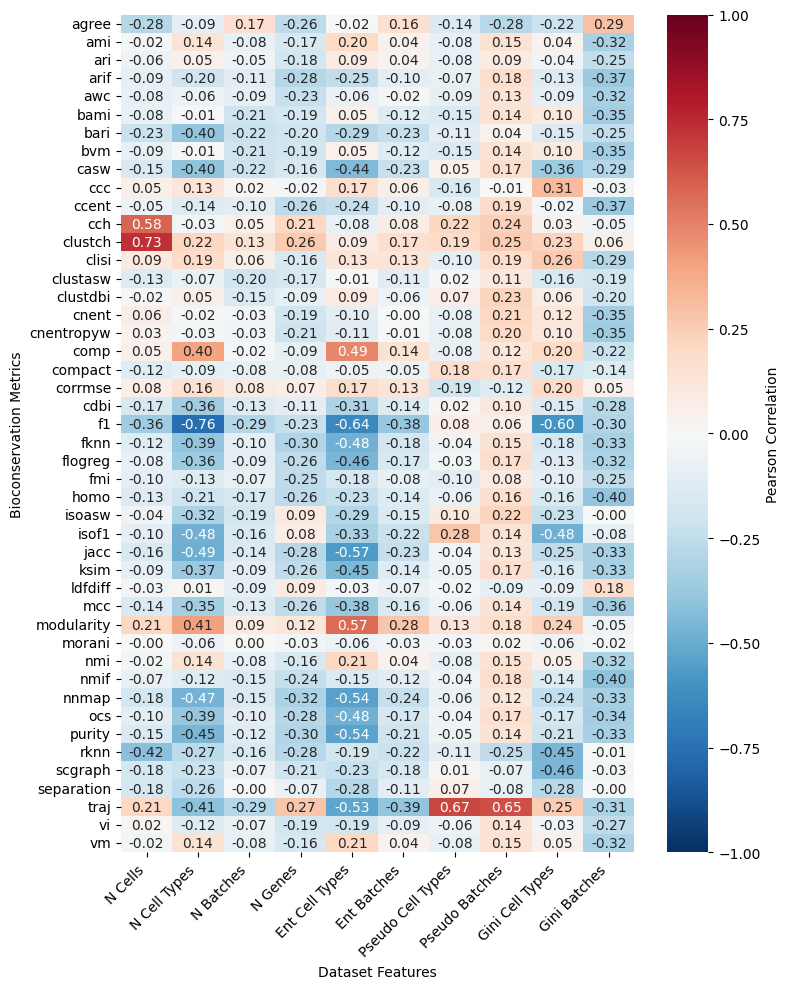

In [26]:
mean_rows = [row for row in feature_corrs.index if row.endswith('_mean')]
df_means = feature_corrs.loc[mean_rows]

df_means.index = [idx.replace('_corr_mean', '').replace('_', ' ').title() for idx in df_means.index]
df_means = df_means.T
df_means = df_means[df_means.index.isin(bio)]

plt.figure(figsize=(8, 10))
sns.heatmap(
    df_means,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    cbar_kws={'label': 'Pearson Correlation'},
    vmax=1, vmin=-1
)

plt.ylabel("Bioconservation Metrics")
plt.xlabel("Dataset Features")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

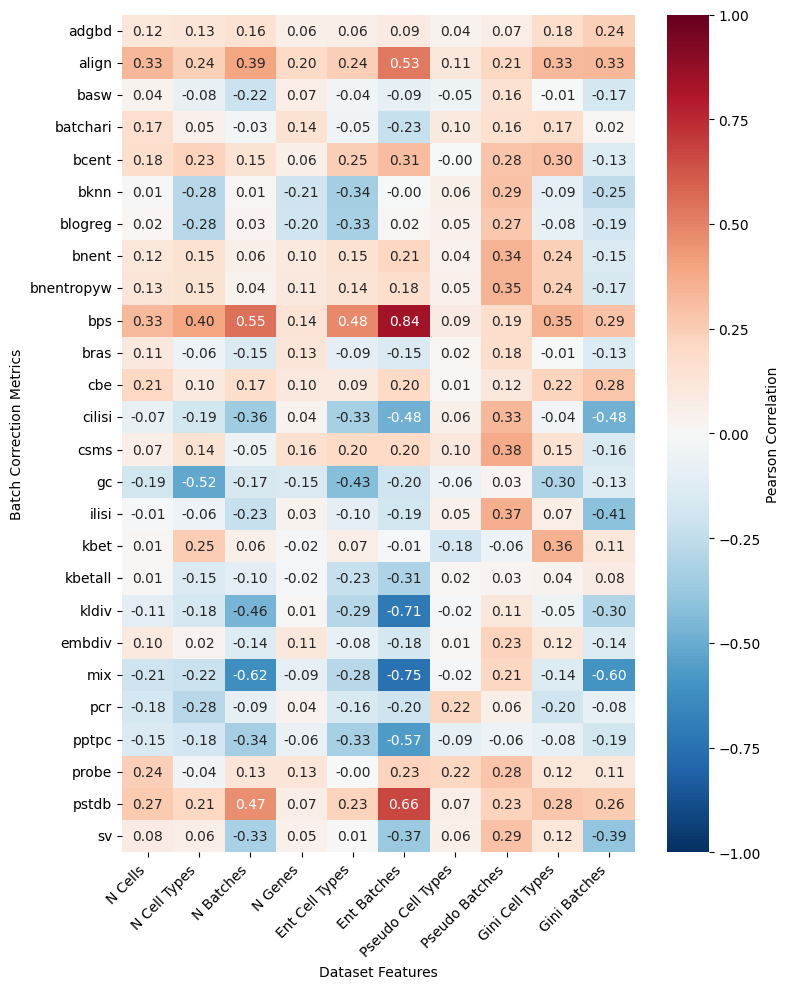

In [27]:
mean_rows = [row for row in feature_corrs.index if row.endswith('_mean')]
df_means = feature_corrs.loc[mean_rows]

df_means.index = [idx.replace('_corr_mean', '').replace('_', ' ').title() for idx in df_means.index]
df_means = df_means.T
df_means = df_means[df_means.index.isin(batch)]

plt.figure(figsize=(8, 10))
sns.heatmap(
    df_means,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    cbar_kws={'label': 'Pearson Correlation'},
    vmax=1, vmin=-1
)

plt.ylabel("Batch Correction Metrics")
plt.xlabel("Dataset Features")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Metric coefficient of variations against dataset characteristics

In [22]:
cvs = df_full[df_full['Integration'] != 'oneBigBlob-1'].pivot(index=['Dataset', 'Integration'], columns='Metric', values="Value").groupby('Dataset')[df_full.Metric.unique()].apply(
    lambda x: x.std() / x.mean().abs()
).reset_index()
cvs['Dataset'] = cvs['Dataset'].replace({
    'nph_cerebellum': 'nhp_cerebellum',
    'nph_liver': "nhp_liver"
})

mean_cv_per_metric = cvs[df_full.Metric.unique()].mean().sort_values(ascending=False)
mean_cv_per_metric.loc[['f1', 'mcc', 'arif', 'ccent', 'homo', 'nmif', 'jacc', 'purity']]

Metric
f1        0.234816
mcc       0.183329
arif      0.228926
ccent     0.135202
homo      0.190749
nmif      0.205448
jacc      0.171324
purity    0.108491
dtype: float64

In [35]:
df_info = data_info.drop(['Celltype keys', 'Batch keys', 'UMIs per batch'], axis=1)
df_combined = cvs.merge(df_info, on='Dataset').set_index('Dataset')

metric_cols = list(df_full.Metric.unique())
char_cols = [c for c in df_info.columns if c != 'Dataset']

corr_matrix = df_combined.corr(method='spearman')
result = corr_matrix.loc[metric_cols, char_cols]

<Figure size 1000x800 with 0 Axes>

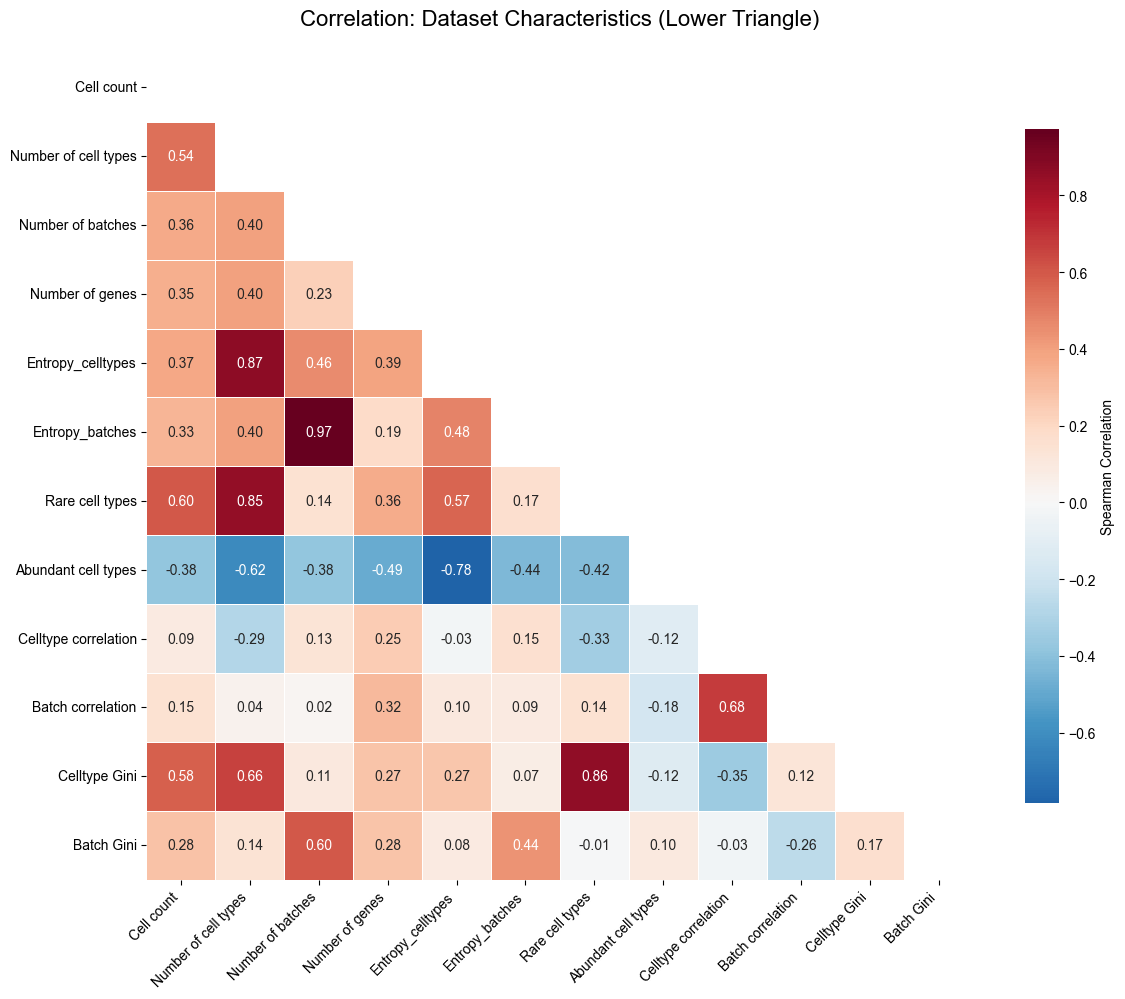

In [36]:
corr = df_info.corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 10))

ax = sns.heatmap(
    corr,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8, "label": "Spearman Correlation"}
)

ax.grid(False)
plt.title("Correlation: Dataset Characteristics (Lower Triangle)", fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# UNUSED
plt.figure(figsize=(10, 15))

tp = result.loc[bio_order]
tp.drop('Number of genes',axis=1, inplace=True)

original_names = tp.index.tolist() 
tp.index = tp.index.str.upper()

ax = sns.heatmap(tp, annot=True, fmt=".2f", 
                 cbar_kws={'label': 'Pearson Correlation'},
                 cmap="RdBu_r", center=0)

ax.grid(False)

y_labels = ax.get_yticklabels()
for i, label in enumerate(y_labels):
    original_name = bio_order[i]
    category = grouping.get(original_name, 'unknown')
    
    color = group_colors.get(category, 'black')
    
    label.set_color(color)

plt.title("Correlation: Metric CV vs. Dataset Characteristics", fontsize=12)
plt.ylabel("Metrics (Discriminative Power)", fontsize=12)
plt.xlabel("Dataset Features", fontsize=12)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [ ]:
# UNUSED
plt.figure(figsize=(9, 9))

tp = result.loc[batch]
tp.drop('Number of genes',axis=1, inplace=True)

tp.index = tp.index.str.upper()
ax = sns.heatmap(tp, annot=True, fmt=".2f", 
                 cbar_kws={'label': 'Pearson Correlation'},
                 cmap="RdBu_r", center=0)

ax.grid(False)

plt.title("Correlation: Metric CV vs. Dataset Characteristics")
plt.ylabel("Metrics (Discriminative Power)")
plt.xlabel("Dataset Features")
plt.xticks(rotation=45, ha='right')

plt.show()

## Plotting coefficient of variations per metric

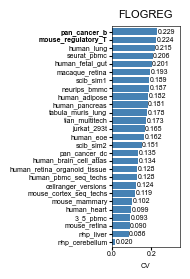

In [33]:
t = 'flogreg'
ddf = cvs[['Dataset', t]].sort_values(t)

highlight = {'pan_cancer_b', 'mouse_regulatory_T'}

fig, ax = plt.subplots(figsize=(2, len(ddf) * 0.07 + 1))
bars = ax.barh(ddf['Dataset'], ddf[t], color='steelblue')
ax.margins(y=0.01)

for bar, value in zip(bars, ddf[t]):
    ax.text(
        bar.get_width() + ddf[t].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.3f}',
        va='center', ha='left', fontsize=5
    )
ax.set_xlabel('CV', fontsize=5)
ax.set_title(t.upper(), fontsize=8)
ax.set_xlim(0, ddf[t].max() * 1.5)
ax.tick_params(axis='both', which='major', width=.8, length=2, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)

for label, dataset in zip(ax.get_yticklabels(), ddf['Dataset']):
    if dataset.strip() in highlight:
        label.set_fontweight('bold')

plt.tight_layout()
plt.savefig(f'../publication_figures/{t}_dataset_cvs.png', dpi=300, bbox_inches='tight')
plt.show()

In [9]:
cvs = df_full[df_full['Integration'] != 'oneBigBlob-1'].pivot(index=['Dataset', 'Integration'], columns='Metric', values="Value").groupby('Dataset')[df_full.Metric.unique()].apply(
    lambda x: x.std() / x.mean().abs()
).reset_index()
mean_cv_per_metric = cvs[df_full.Metric.unique()].mean().sort_values(ascending=False)
cv_plot = mean_cv_per_metric.loc[bio + both].sort_values(ascending=False)
cv_plot = cv_plot.reset_index().rename({0: 'CV'}, axis=1)

In [10]:
g0 = 'Clusters-as-predictions\n& kNN'
g1 = 'Logistic regression'
g2 = 'Cluster-label similarity'
g3 = 'Cell types as clusters'
g4 = 'Isolated labels & GC'
g5 = 'Cluster quality 1'
g6 = 'Joint bioconservation\n& batch correction'
g7 = 'Finer-grained biology'
g8 = 'Cluster quality 2'
grouping_map = {
    'fmi': g2, 'awc': g2, 'ari': g2, 'vi': g2, 'nmi': g2, 'ami': g2, 'vm':g2, 
    'bari': g2, 'bami': g2, 'bvm': g2, 
    'isoasw': g4, 'gc': g4, 'isof1': g4, 
    'casw': g3, 'cdbi': g3, 'cch': g3, 
    'blogreg': g1, 'flogreg': g1, 
    'clisi': g0, 'fknn': g0, 'ksim': g0, 'ocs': g0, 'nnmap': g0, 'cnent': g0, 
    'cnentropyw': g0, 'bknn': g0, 'f1': g0, 'mcc': g0, 'jacc': g0, 'purity': g0, 
    'ccent': g0, 'homo': g0, 'arif': g0, 'nmif': g0, 
    'clustch': g5, 'clustasw': g5, 'clustdbi': g5, 
    'comp': g6, 'pptpc': g6, 'pstdb': g6, 
    'ldfdiff': g7, 'agree': g7, 'morani': g7, 'rknn': g7, 'ccc': g7, 
    'scgraph': g7, 'corrmse': g7, 'traj': g7, 
    'modularity': g8, 'compact': g8, 'separation': g8
}

group_colors = {
    g0: '#8dd3c7', g1: '#ffffb3', g2: '#bebada', 
    g3: '#fb8072', g4: '#80b1d3', g5: '#fdb462', 
    g6: '#b3de69', g7: '#fccde5', g8: '#d9d9d9'
}

cv_plot['Group'] = cv_plot['Metric'].replace(grouping_map)

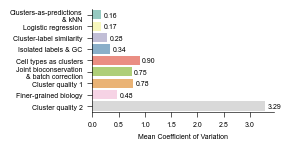

In [11]:
df_plot = cv_plot.groupby('Group')['CV'].mean()
df_plot = df_plot.loc[[g0, g1, g2, g4,g3,g6,g5,g7,g8]]

plt.figure(figsize=(3, 1.6))
bar_colors = [group_colors.get(group_name, '#9fb6e9') for group_name in df_plot.index]
ax = sns.barplot(
    x=df_plot.values, 
    y=df_plot.index,
    palette=bar_colors,
    hue=df_plot.index
)
ax.tick_params(axis='both', labelsize=5, width=.45)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Mean Coefficient of Variation', fontsize=5)
plt.ylabel('', fontsize=5)

for i, v in enumerate(df_plot.values):
    ax.text(v + 0.05, i, f'{v:.2f}', color='black', va='center', fontsize=5)

for spine in ax.spines.values():
    spine.set_linewidth(.45)
plt.tight_layout()
limits = ax.get_xlim()
# plt.savefig('../publication_figures/cv_bioconservation.svg', dpi=250, bbox_inches='tight')
plt.show()

(np.float64(0.0), np.float64(5.189770325374888))


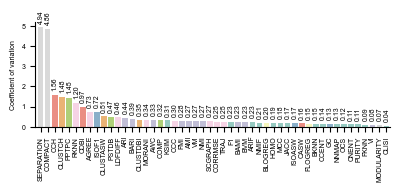

In [12]:
fig, ax = plt.subplots(figsize=(4.1, 2))

cv_plot['Metric'] = cv_plot['Metric'].str.upper()
sns.barplot(
    data=cv_plot,
    x="Metric",
    y="CV",
    hue="Group",
    palette=group_colors,
    dodge=False,
    ax=ax,
    legend=False,
)
sns.despine(ax=ax, top=True, right=True)
ax.tick_params(axis='both', labelsize=5)
print(ax.get_ylim())
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=5,
        rotation=90
    )
plt.ylabel('Coefficient of variation', fontsize=5)
plt.xlabel('')
plt.xticks(rotation=90)
plt.xlim(-.75, None)
plt.tight_layout()
plt.savefig('../publication_figures/full_bio_cvs.svg', dpi=300, bbox_inches='tight')
plt.show()

In [14]:
cv_plot2 = mean_cv_per_metric.loc[batch + both].sort_values(ascending=False)
cv_plot2 = cv_plot2.reset_index().rename({0: 'CV'}, axis=1)
g0 = 'Primarily\nbioconservation'
g1 = 'BASW & SV'
g2 = 'Clustering metrics'
g3 = 'PCR & PROBELR'
g4 = 'Joint bioconservation &\nbatch correction'
g5 = 'Unique metrics'
g6 = 'kNN metrics'

grouping_map = {
    'mix': g6, 'align': g6, 'ilisi': g6, 'bnent': g6, 'kldiv': g6,
    'adgbd': g6, 'kbetall': g6, 'cilisi': g6, 'csms': g6, 'kbet': g6,
    'bras': g5, 'embdiv': g5, 'probe': g5, 'batchari': g2, 'pcr': g3,
    'probelr': g3, 'proberf': g5,
    'bp': g2, 'bcent': g2, 'cre': g2,
    'pstdb': g4, 'pptpc': g4,
    'basw': g1, 'sv': g1,
    'gc': g0, 'bknn': g0, 'blogreg': g0
}

group_colors2 = {
    g0: '#a65628', g1: '#FFFF33', g2: '#377EB8', 
    g3: '#984EA3', g4: '#FF7F00', g5: '#4DAF4A',
    g6: '#e41a1c'
}

cv_plot2['Group'] = cv_plot2['Metric'].replace(grouping_map)

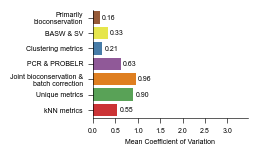

In [16]:
df_plot = cv_plot2.groupby('Group')['CV'].mean()
df_plot = df_plot.loc[[g0, g1, g2,g3, g4,g5, g6]]

plt.figure(figsize=(2,1.4))
bar_colors = [group_colors2.get(group_name, '#9fb6e9') for group_name in df_plot.index]

ax = sns.barplot(
    x=df_plot.values,
    y=df_plot.index,
    palette=bar_colors,
    hue=df_plot.index
)
ax.tick_params(axis='both', labelsize=5, width=.45)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xlabel('Mean Coefficient of Variation', fontsize=5)
plt.ylabel('', fontsize=10)
for spine in ax.spines.values():
    spine.set_linewidth(.45)

for i, v in enumerate(df_plot.values):
    ax.text(v + 0.05, i, f'{v:.2f}', color='black', va='center', fontsize=5)
# plt.xticks(rotation=90)
plt.xlim(0, 3.455462400933679)
# plt.savefig('../publication_figures/cv_batch.svg', dpi=250, bbox_inches='tight')

plt.show()

/tmp/ipykernel_706599/4281769856.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90, ha="center", va="top")
/tmp/ipykernel_706599/4281769856.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90, ha="center", va="top")


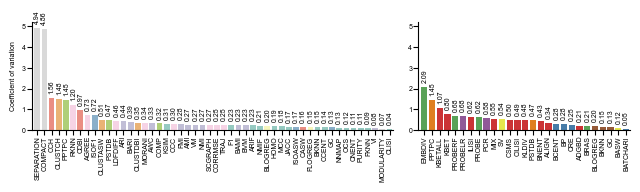

In [17]:
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(6.5, 2), gridspec_kw={"width_ratios": [4.1, 2.4]}
)

cv_plot["Metric"] = cv_plot["Metric"].str.upper()
sns.barplot(
    data=cv_plot,
    x="Metric",
    y="CV",
    hue="Group",
    palette=group_colors,
    dodge=False,
    ax=ax1,
    legend=False,
)
sns.despine(ax=ax1, top=True, right=True)
ax1.tick_params(axis="both", labelsize=5, pad=1)
for container in ax1.containers:
    ax1.bar_label(container, fmt="%.2f", padding=3, fontsize=5, rotation=90)
ax1.set_ylabel("Coefficient of variation", fontsize=5)
ax1.set_xlabel("")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=90, ha="center", va="top")
ax1.set_xlim(-0.75, None)

cv_plot2["Metric"] = cv_plot2["Metric"].str.upper()
sns.barplot(
    data=cv_plot2,
    x="Metric",
    y="CV",
    hue="Group",
    palette=group_colors2,
    dodge=False,
    ax=ax2,
    legend=False,
)
sns.despine(ax=ax2, top=True, right=True)
ax2.tick_params(axis="both", labelsize=5, pad=1)
for container in ax2.containers:
    ax2.bar_label(container, fmt="%.2f", padding=3, fontsize=5, rotation=90)
ax2.set_ylabel("", fontsize=5)
ax2.set_xlabel("")
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90, ha="center", va="top")
ax2.set_xlim(-0.75, None)
ax2.set_ylim(0, 5.189770325374888)

plt.tight_layout()
plt.savefig("../publication_figures/combined_cvs.svg", dpi=300, bbox_inches="tight")
plt.show()